<a href="https://colab.research.google.com/github/aayush-r-a-j/Stock_Data_Analysis/blob/main/Stocks_Analysis_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install yfinance -q

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

stocks = ["ITC.NS", "TATASTEEL.NS", "INFY.NS", "HDFCBANK.NS", "SUNPHARMA.NS"]

data = yf.download(stocks, start="2023-10-12", end="2026-10-11")["Close"]

print(data.head())
print(data.shape)
print(data.isna().sum())

/tmp/ipykernel_481/472828721.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(stocks, start="2023-10-12", end="2026-10-11")["Close"]
[*********************100%***********************]  5 of 5 completed

Ticker      HDFCBANK.NS      INFY.NS      ITC.NS  SUNPHARMA.NS  TATASTEEL.NS
Date                                                                        
2023-10-12   742.017334  1333.264282  386.860138   1100.026245    118.164139
2023-10-13   735.266724  1302.013916  384.842957   1114.526001    117.366371
2023-10-16   732.322327  1304.743164  385.357971   1104.794434    119.196548
2023-10-17   737.875977  1312.294312  389.220612   1106.254272    119.571968
2023-10-18   727.606506  1310.565552  387.675568   1122.408203    119.290398
(739, 5)
Ticker
HDFCBANK.NS     0
INFY.NS         0
ITC.NS          0
SUNPHARMA.NS    0
TATASTEEL.NS    0
dtype: int64


In [2]:
summary = data.agg(["mean", "max", "min"]).round(2)
print(summary)

Ticker  HDFCBANK.NS  INFY.NS  ITC.NS  SUNPHARMA.NS  TATASTEEL.NS
mean         829.44  1458.55  369.44       1653.66        158.32
max          996.42  1901.08  463.95       2001.10        216.66
min          662.64   985.30  255.00       1059.35        109.44


In [3]:
returns = data.pct_change().dropna()
print((returns * 100).round(2).head())

Ticker      HDFCBANK.NS  INFY.NS  ITC.NS  SUNPHARMA.NS  TATASTEEL.NS
Date                                                                
2023-10-13        -0.91    -2.34   -0.52          1.32         -0.68
2023-10-16        -0.40     0.21    0.13         -0.87          1.56
2023-10-17         0.76     0.58    1.00          0.13          0.31
2023-10-18        -1.39    -0.13   -0.40          1.46         -0.24
2023-10-19        -0.32    -0.48   -0.28         -1.03         -0.87


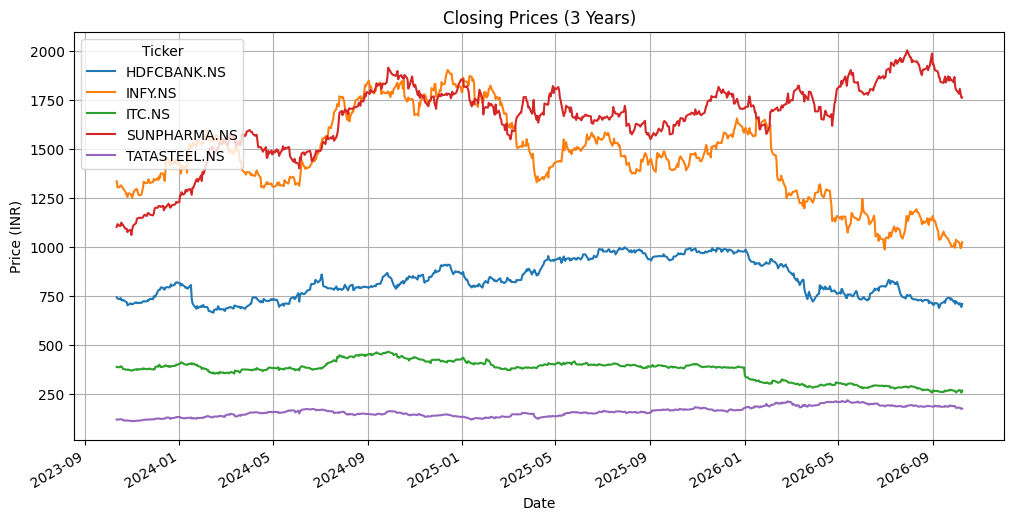

In [4]:
data.plot(figsize=(12, 6), title="Closing Prices (3 Years)")
plt.ylabel("Price (INR)")
plt.grid(True)
plt.show()

              Daily Volatility %  Annual Volatility %
Ticker                                               
TATASTEEL.NS                1.76                27.94
INFY.NS                     1.67                26.44
HDFCBANK.NS                 1.29                20.43
SUNPHARMA.NS                1.24                19.73
ITC.NS                      1.21                19.28


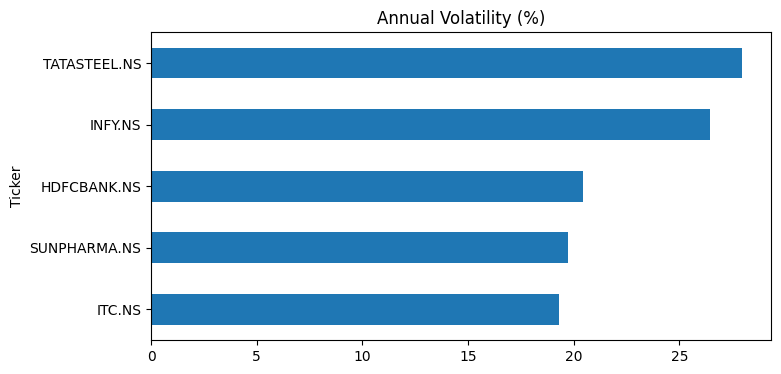

In [5]:
daily_vol = returns.std()
annual_vol = daily_vol * np.sqrt(252)

vol_table = pd.DataFrame({
    "Daily Volatility %": (daily_vol * 100).round(2),
    "Annual Volatility %": (annual_vol * 100).round(2)
})
print(vol_table.sort_values("Annual Volatility %", ascending=False))

(annual_vol * 100).sort_values().plot(kind="barh", figsize=(8, 4), title="Annual Volatility (%)")
plt.show()

Ticker        HDFCBANK.NS  INFY.NS  ITC.NS  SUNPHARMA.NS  TATASTEEL.NS
Ticker                                                                
HDFCBANK.NS          1.00     0.19    0.22          0.12          0.34
INFY.NS              0.19     1.00    0.14          0.13          0.18
ITC.NS               0.22     0.14    1.00          0.14          0.20
SUNPHARMA.NS         0.12     0.13    0.14          1.00          0.27
TATASTEEL.NS         0.34     0.18    0.20          0.27          1.00


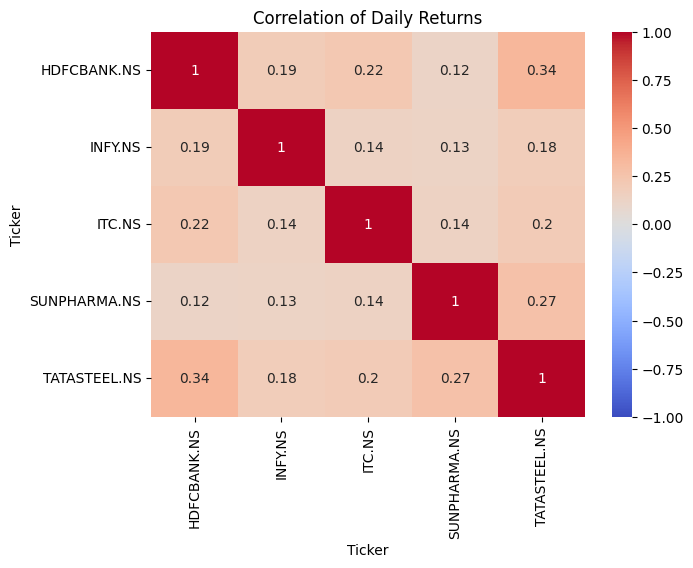

In [6]:
import seaborn as sns

corr = returns.corr().round(2)
print(corr)

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation of Daily Returns")
plt.show()

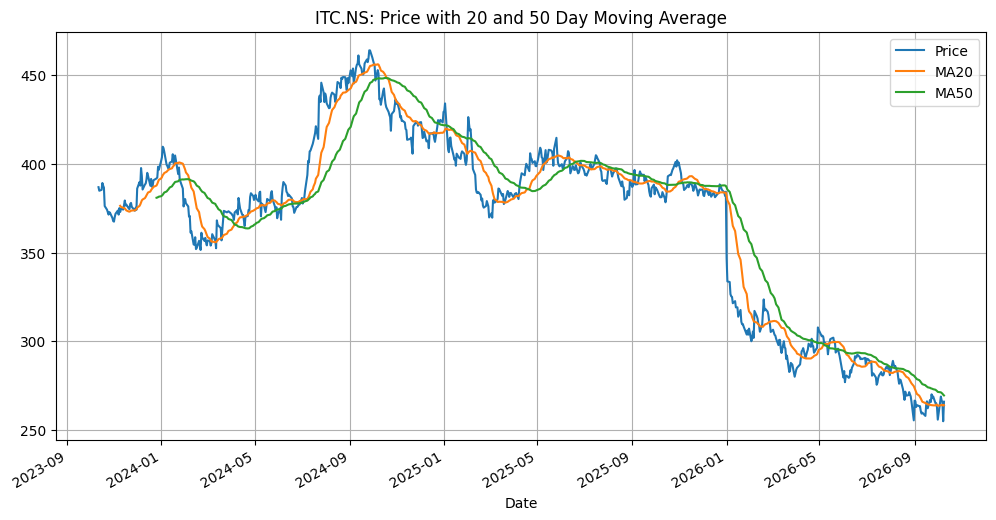

In [7]:
stock = "ITC.NS"   # change this to any stock you like

ma = pd.DataFrame({"Price": data[stock]})
ma["MA20"] = ma["Price"].rolling(20).mean()
ma["MA50"] = ma["Price"].rolling(50).mean()

ma.plot(figsize=(12, 6), title=f"{stock}: Price with 20 and 50 Day Moving Average")
plt.grid(True)
plt.show()

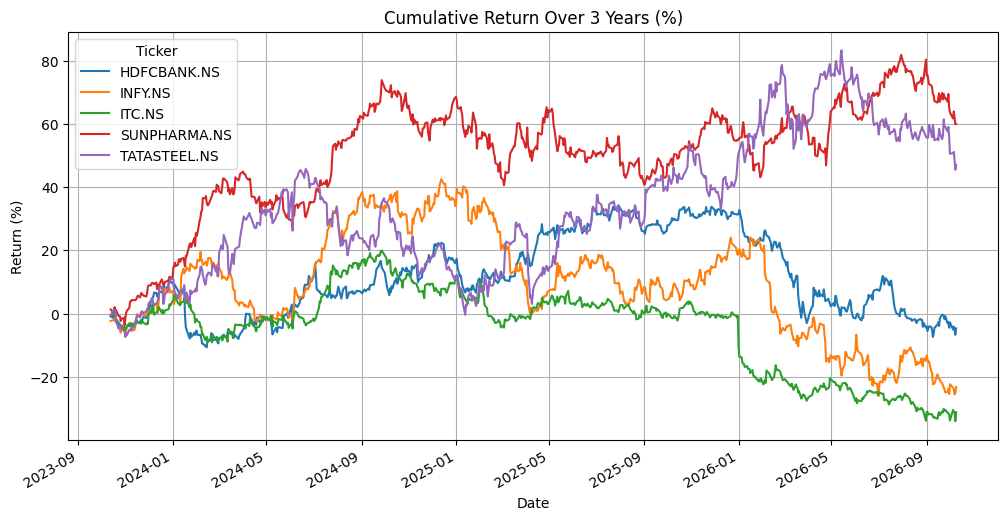

Ticker
SUNPHARMA.NS    60.00
TATASTEEL.NS    47.08
HDFCBANK.NS     -4.69
INFY.NS        -23.24
ITC.NS         -31.24
Name: 2026-10-09 00:00:00, dtype: float64


In [8]:
cumulative = (1 + returns).cumprod() - 1

(cumulative * 100).plot(figsize=(12, 6), title="Cumulative Return Over 3 Years (%)")
plt.ylabel("Return (%)")
plt.grid(True)
plt.show()

print((cumulative.iloc[-1] * 100).round(2).sort_values(ascending=False))

/tmp/ipykernel_481/3632801420.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  comm = yf.download(["CL=F", "GC=F"], start="2023-10-12", end="2026-10-11")["Close"]
[*********************100%***********************]  2 of 2 completed
/tmp/ipykernel_481/3632801420.py:5: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  combined_returns = combined.pct_change().dropna()


Ticker        Crude Oil  Gold
Ticker                       
HDFCBANK.NS       -0.13  0.11
INFY.NS            0.06 -0.01
ITC.NS            -0.09  0.06
SUNPHARMA.NS      -0.04  0.01
TATASTEEL.NS      -0.03  0.21
Crude Oil          1.00 -0.02
Gold              -0.02  1.00


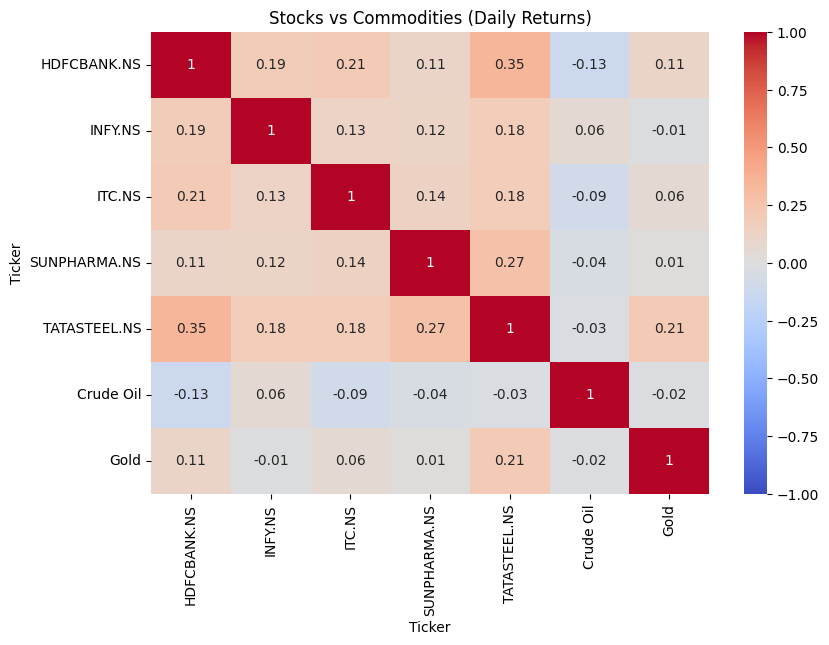

In [9]:
comm = yf.download(["CL=F", "GC=F"], start="2023-10-12", end="2026-10-11")["Close"]
comm = comm.rename(columns={"CL=F": "Crude Oil", "GC=F": "Gold"})

combined = data.join(comm, how="inner")
combined_returns = combined.pct_change().dropna()

print(combined_returns.corr().round(2)[["Crude Oil", "Gold"]])

plt.figure(figsize=(9, 6))
sns.heatmap(combined_returns.corr().round(2), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Stocks vs Commodities (Daily Returns)")
plt.show()